## 1. Análise Exploratória de Dados (EDA) e Pré-processamento

### 1.1 Carregamento e simulação de dados sujos
Foi analisada uma base de Manutenção Preditiva Industrial contendo 10.000 registros de telemetria de sensores (temperaturas, rotação, torque e desgaste de ferramenta) e o indicador de falha (Target).

Como o dataset original é sintético e livre de ruídos, realizamos uma injeção de inconsistências para simular um cenário real:
* **Valores ausentes (`NaN`):** inseridos em variáveis numéricas e categóricas;
* **Erros de formatação:** espaços em branco e variações de maiúsculas/minúsculas em "Failure Type";
* **Outliers discrepantes:** leituras absurdas de sensor, como RPM negativo, pico de 8.500 rpm e torque de 240 Nm por exemplo;
* **Duplicatas:** 20 registros repetidos adicionados no final.

In [ ]:
# Evita os warnings
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module=r"jupyter_client\..*"
)

In [ ]:
# Bibliotecas base e visualização
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LogNorm

# Pré-processamento, pipeline e validação
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler

# (K-Means e Apriori)
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.cluster import KMeans

# (KNN)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    silhouette_score,
)
from sklearn.neighbors import KNeighborsClassifier

sns.set_theme(style="whitegrid")

# Carregamento direto via GitHub Raw
url_dados = 'https://raw.githubusercontent.com/jaysri125278/Predictive-Maintenance/main/MDT32_final_project_dataset.csv'
colunas = [
    'UDI', 'Product ID', 'Type',
    'Air temperature [K]', 'Process temperature [K]',
    'Rotational speed [rpm]', 'Torque [Nm]',
    'Tool wear [min]', 'Target', 'Failure Type'
]

df_bruto = pd.read_csv(url_dados, usecols=colunas)


# INJEÇÃO CONTROLADA DE RUÍDOS (Conforme requisito de Dataset Sintético)
np.random.seed(42)
df_sujo = df_bruto.copy()

# 1.1 Valores ausentes (NaN) em variáveis numéricas
for col in ['Air temperature [K]', 'Torque [Nm]', 'Tool wear [min]']:
    idx_nulos = np.random.choice(df_sujo.index, size=200, replace=False)
    df_sujo.loc[idx_nulos, col] = np.nan

# 1.2 Valores ausentes (NaN) em variáveis categóricas (~1.5% dos registros)
for col in ['Type', 'Failure Type']:
    idx_nulos_cat = np.random.choice(df_sujo.index, size=150, replace=False)
    df_sujo.loc[idx_nulos_cat, col] = np.nan

# 3. Inconsistências de formatação em strings (espaços extras e minúsculas/maiúsculas)
idx_sujo_fail = df_sujo[df_sujo['Failure Type'] == 'No Failure'].sample(100, random_state=42).index
df_sujo.loc[idx_sujo_fail[:50], 'Failure Type'] = 'no failure'
df_sujo.loc[idx_sujo_fail[50:], 'Failure Type'] = ' No Failure '

# 4. Outliers discrepantes (erros de leitura de sensores)
idx_outliers = np.random.choice(df_sujo.index, size=25, replace=False)
df_sujo.loc[idx_outliers[:10], 'Rotational speed [rpm]'] = 8500   # Pico irreal de RPM
df_sujo.loc[idx_outliers[10:15], 'Rotational speed [rpm]'] = -150 # Leitura negativa impossível
df_sujo.loc[idx_outliers[15:], 'Torque [Nm]'] = 240.0

# 5. Registros duplicados (20 linhas duplicadas inseridas no final)
duplicatas_artificiais = df_sujo.sample(20, random_state=42)
df_sujo = pd.concat([df_sujo, duplicatas_artificiais], ignore_index=True)

### 1.2 Diagnóstico de Qualidade e Identificação Visual de Outliers
Em seguida, foi verificada a integridade do dataset (`df_sujo`) contabilizando o volume total de valores ausentes e linhas duplicadas e também a partir da análise gráfica, usando **Boxplots** . Em seguida, extraímos as medidas de estatística descritiva (média, mediana, quartis e extremos) também exibida para análise.

--- RESUMO (DADOS SUJOS) ---


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],9800.0,300.003571,2.000359,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10020.0,310.006407,1.483630,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10020.0,1544.845210,286.090407,-150.0,1423.0,1503.0,1612.0,8500.0
Torque [Nm],9820.0,40.194002,11.834568,3.8,33.2,40.1,46.8,240.0
Tool wear [min],9820.0,108.162627,63.592676,0.0,53.0,108.0,162.0,251.0


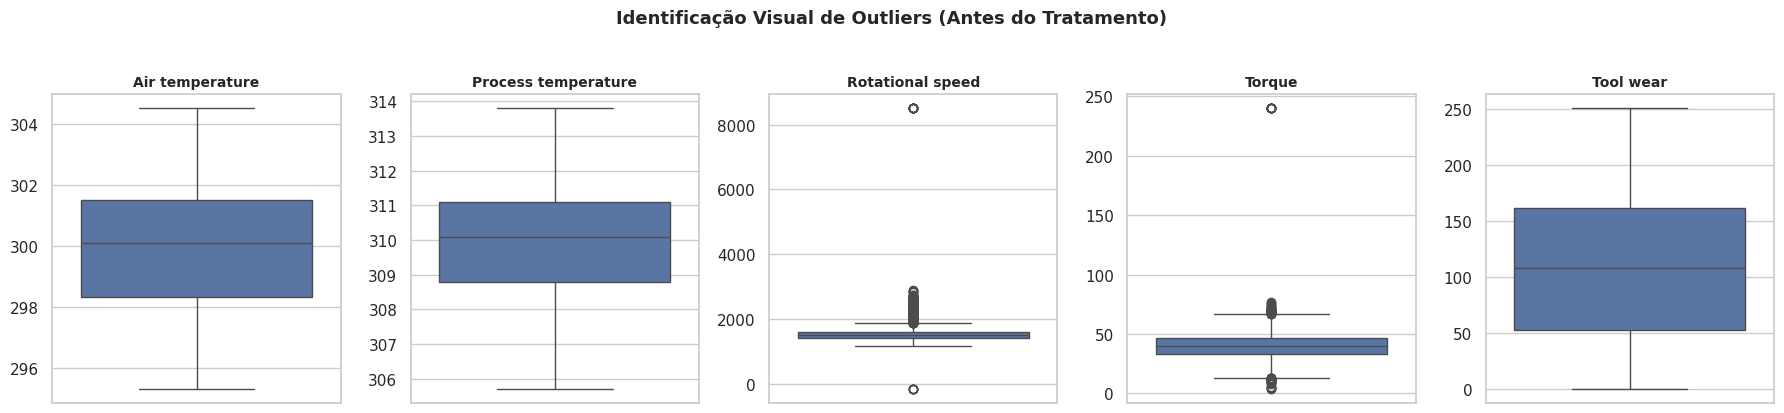

In [ ]:
# ESTATÍSTICA DESCRITIVA E ANÁLISE VISUAL (EDA)
num_cols = [
    'Air temperature [K]', 'Process temperature [K]',
    'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]'
]

print("--- RESUMO (DADOS SUJOS) ---")
print(f"Total de nulos antes da limpeza: {df_sujo.isnull().sum().sum()}")
print(f"Total de duplicatas antes da limpeza: {df_sujo.duplicated().sum()}\n")
display(df_sujo[num_cols].describe().T)

# 1. Boxplots para visualizar os outliers injetados
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df_sujo[col], ax=axes[i], color='#4C72B0')
    axes[i].set_title(col.split(' [')[0], fontsize=10, weight='bold')
    axes[i].set_ylabel('')
plt.suptitle('Identificação Visual de Outliers (Antes do Tratamento)', fontsize=13, weight='bold', y=1.03)
plt.tight_layout()
plt.show()

### 1.3 Limpeza dos Dados
Nesta etapa é gerado o dataset tratado (`df_limpo`) e, na sequência, já é preparado uma versão específica para o modelo supervisionado (`df_model_knn`):
1. **Remoção de duplicatas** e padronização textual (`strip`, `upper` e `title`) nas colunas categóricas;
2. **Tratamento de outliers** via limites do Intervalo Interquartil (IQR);
3. **Input de valores ausentes** com mediana (variável numérica) e moda (variável categórica);
4. **Codificação e prevenção de vazamento:** remoção de identificadores (`UDI`, `Product ID`) e de `Failure Type` (que descreve a falha já ocorrida), além da aplicação de **One-Hot Encoding** (`0` e `1`) na coluna `Type`.

In [ ]:
# 1.4 TRATAMENTO E LIMPEZA DOS DADOS
df_limpo = df_sujo.copy()
df_limpo = df_limpo.drop_duplicates().reset_index(drop=True) # 1. Remover registros duplicados

# 2. Padronizar variáveis categóricas (remover espaços e padronizar caixa)
df_limpo['Type'] = df_limpo['Type'].str.strip().str.upper()
df_limpo['Failure Type'] = df_limpo['Failure Type'].str.strip().str.title()

# 3. Tratar Outliers via IQR (Capping/Winsorização)
df_limpo.loc[df_limpo['Rotational speed [rpm]'] < 0, 'Rotational speed [rpm]'] = np.nan
for col in ['Rotational speed [rpm]', 'Torque [Nm]']:
    Q1 = df_limpo[col].quantile(0.25)
    Q3 = df_limpo[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    df_limpo[col] = np.clip(df_limpo[col], limite_inf, limite_sup)

# 4. Preencher valores ausentes (Mediana para numéricas, Moda para categóricas)
for col in num_cols:
    df_limpo[col] = df_limpo[col].fillna(df_limpo[col].median())

for col in ['Type', 'Failure Type']:
    df_limpo[col] = df_limpo[col].fillna(df_limpo[col].mode()[0])

print("Nulos após limpeza:", df_limpo.isnull().sum().sum())
print("Duplicatas após limpeza:", df_limpo.duplicated().sum())

# 1.5 ONE-HOT ENCODING E EXIBIÇÃO APÓS O TRATAMENTO DE DADOS

df_model_knn = df_limpo.drop(columns=['UDI', 'Product ID', 'Failure Type']).copy()
df_model_knn = pd.get_dummies(df_model_knn, columns=['Type'], dtype=int)
display(df_model_knn.head())

Nulos após limpeza: 0
Duplicatas após limpeza: 0


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Type_H,Type_L,Type_M
0,298.1,308.6,1551.0,42.8,0.0,0,0,0,1
1,298.2,308.7,1408.0,46.3,3.0,0,0,1,0
2,298.1,308.5,1498.0,49.4,5.0,0,0,1,0
3,298.2,308.6,1433.0,39.5,7.0,0,0,1,0
4,298.2,308.7,1408.0,40.0,9.0,0,0,1,0


### 1.4 Justificativas

* **Tratamento de Valores Nulos e Duplicatas:** As 20 linhas duplicadas foram excluídas para evitar viés nas distribuições, e também optou-se pela imputação via **mediana** nas variáveis numéricas (por ser uma métrica robusta e não sofrer distorção com assimetrias) e via **moda** nas variáveis categóricas, por ser uma variável de String, que pode ser contada pela sua frequência (`Type` e `Failure Type`). A imputação foi preferida em relação à exclusão de linhas para preservar o tamanho da amostra, dado que as falhas de máquina (`Target = 1`) são eventos raros na base.
* **Tratamento de Outliers (Método IQR):** Leituras fisicamente impossíveis (rotação negativa) foram convertidas em nulo, enquanto os extremos superiores de `Rotational speed [rpm]` e `Torque [Nm]` foram limitados pelos tetos do **Intervalo Interquartil ($Q_3 + 1,5 \times IQR$)**.
* **Necessidade de Padronização de Escala:** Os sensores operam em ordens de grandeza muito distintas (por exemplo, `Rotational speed` com `1.500 rpm` contra `Torque` na faixa de `40 Nm` e variáveis binárias `0/1` de `Type`).

# 2. Aprendizado Não Supervisionado

- K-means: Pelo tipo de falha
- Apriore: Fazer uma análise dos fatores mais relevantes para quebra do equipamento

- site de refereência apriori https://www.datacamp.com/pt/tutorial/apriori-algorithm

## Etapa do K-Means: Descoberta de Perfis de Desgaste (Não Supervisionado)

Nesta etapa, aplicamos o algoritmo **K-Means** para segmentar o parque de máquinas da fábrica com base nos dados de telemetria dos sensores IoT (`Air temperature`, `Process temperature`, `Rotational speed`, `Torque` e `Tool wear`).

* **Abordagem Não Supervisionada:** O modelo agrupa os registros por similaridade matemática sem utilizar o gabarito prévio de falhas, descobrindo perfis ocultos de operação de forma autônoma.
* **Pipeline Blindado:** Utiliza `SimpleImputer` (preenchimento por mediana) e `RobustScaler` (escala resistente a *outliers*) encapsulados em um único fluxo para garantir a estabilidade do agrupamento e evitar distorções causadas por ruídos nos sensores.
* **Justificativa do Número de Clusters ($K$ Ótimo):**
  * **Método do Cotovelo (Inércia):** Avalia a soma das distâncias quadradas dos pontos em relação aos centroides de seus respectivos grupos. O número ideal de *clusters* é identificado no ponto de inflexão ("cotovelo") da curva, indicando o limite onde adicionar novos grupos deixa de trazer um ganho representativo na compactação dos dados.
  * **Coeficiente de Silhueta (*Silhouette Score*):** Mensura a coesão interna dos *clusters* e o grau de separação em relação aos grupos vizinhos. O pico máximo obtido no intervalo testado confirma a coesão e o isolamento adequado dos perfis operacionais identificados.
* **Interpretação e Negócio:** Os *clusters* gerados são cruzados com as falhas reais da fábrica para traduzir os grupos matemáticos em perfis operacionais práticos (como operação saudável, sobrecarga térmica ou fadiga mecânica), permitindo otimizar o planejamento de manutenções preventivas.
* **Persistência:** O *pipeline* treinado de ponta a ponta é serializado em um arquivo `.joblib` (`modelo_kmeans_manutencao.joblib`) para ser reaproveitado de forma integrada na etapa de simulação e monitoramento em tempo real.

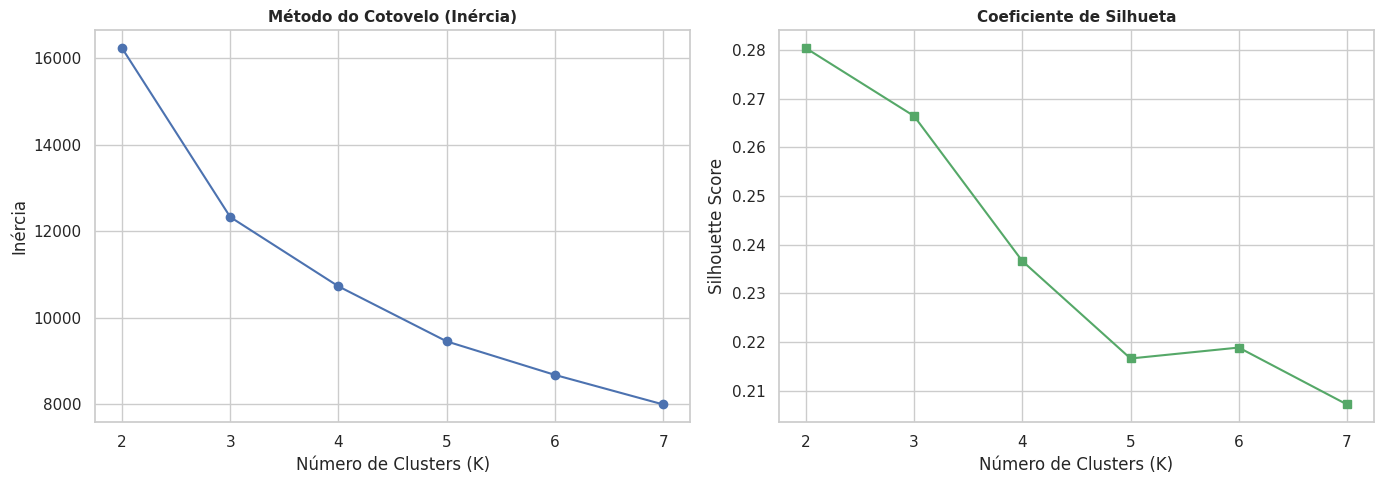

>>> Coeficiente de Silhueta final para K=4: 0.2367 <<<

--- Medianas dos Sensores por Cluster ---


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Cluster_Desgaste,,,,,
0,301.6,311.1,1462.0,43.1,108.0
1,298.3,308.7,1575.0,35.5,108.0
2,300.9,310.8,1744.0,27.5,111.0
3,298.5,308.9,1411.0,47.8,108.0



--- Cruzamento com Tipos de Falha ---


Failure Type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Random Failures,Tool Wear Failure
Cluster_Desgaste,,,,,,
0,103,3249,27,18,10,15
1,0,2338,0,1,2,6
2,0,1737,0,30,3,12
3,7,2335,51,46,3,7



[Sucesso] Pipeline do K-Means salvo como "modelo_kmeans_manutencao.joblib"!


In [ ]:
## K-means

# Seleção das features numéricas
features_sensores = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
]

X_cluster = df_limpo[features_sensores].copy()

# Pipeline de pré-processamento específico para o K-Means
prep_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
])

X_scaled = prep_pipeline.fit_transform(X_cluster)

# Avaliação de K (Método do Cotovelo e Silhueta)
k_range = range(2, 8)
inercias = []
silhuetas = []

for k in k_range:
  km = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = km.fit_predict(X_scaled)
  inercias.append(km.inertia_)
  silhuetas.append(silhouette_score(X_scaled, labels))

# Plotagem dos gráficos para validação
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_range, inercias, marker='o', color='b')
axes[0].set_title('Método do Cotovelo (Inércia)', fontsize=11, weight='bold')
axes[0].set_xlabel('Número de Clusters (K)')
axes[0].set_ylabel('Inércia')
axes[0].grid(True)

axes[1].plot(k_range, silhuetas, marker='s', color='g')
axes[1].set_title(
    'Coeficiente de Silhueta', fontsize=11, weight='bold'
)
axes[1].set_xlabel('Número de Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Treinamento do Pipeline Final do K-Means (Ex: K = 4)
K_ESCOLHIDO = 4

pipeline_kmeans_final = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
    (
        'kmeans',
        KMeans(n_clusters=K_ESCOLHIDO, random_state=42, n_init=10),
    ),
])

# Atribuindo o resultado diretamente no df_limpo
df_limpo['Cluster_Desgaste'] = pipeline_kmeans_final.fit_predict(X_cluster)

# Exibindo métrica final do modelo escolhido
labels_finais = pipeline_kmeans_final.named_steps['kmeans'].labels_
score_final = silhouette_score(X_scaled, labels_finais)
print(
    f'>>> Coeficiente de Silhueta final para K={K_ESCOLHIDO}:'
    f' {score_final:.4f} <<<\n'
)

# Validação e Interpretação dos Clusters com base nos dados limpos
print('--- Medianas dos Sensores por Cluster ---')
perfil_medianas = df_limpo.groupby('Cluster_Desgaste')[features_sensores].median()
display(perfil_medianas)

print('\n--- Cruzamento com Tipos de Falha ---')
display(pd.crosstab(df_limpo['Cluster_Desgaste'], df_limpo['Failure Type']))

# Salvamento do modelo unificado para a etapa de simulação
joblib.dump(pipeline_kmeans_final, 'modelo_kmeans_manutencao.joblib')
print('\n[Sucesso] Pipeline do K-Means salvo como "modelo_kmeans_manutencao.joblib"!')

## Sobre os Limiares (Métricas de Associação)

* **Support (Suporte):** Indica a frequência com que um item ou combinação de itens aparece no *dataset* total. Por exemplo, um suporte de `0,01` indica que a condição de "temperatura alta" ocorreu em 1% dos dados totais.
* **Confidence (Confiança):** Mede a frequência com que a consequência ocorre dado que o antecedente aconteceu (relação entre antecedente e consequência). Por exemplo, uma confiança de `0,07` significa que, em 7% dos casos em que houve temperatura alta, também ocorreu falha.
* **Lift (Elevação):** Avalia a força real da associação entre os eventos ($\text{Confiança} / \text{Suporte}$), seguindo a seguinte regra de interpretação:

| Valor de Lift | Interpretação |
| :--- | :--- |
| **$\text{Lift} < 1$** | **Associação negativa:** A consequência é menos frequente quando o antecedente ocorre. |
| **$\text{Lift} = 1$** | **Independência:** Não há associação estatística entre antecedente e consequência nos dados. |
| **$\text{Lift} > 1$** | **Associação positiva:** A consequência é mais frequente quando o antecedente ocorre. |

---

## Definição dos Valores *Targets*

Para estabelecer os limiares que serviram de base na construção do `df_apriori`, utilizaram-se as métricas estatísticas `.max()` e `.mean()` do *dataset* original. O objetivo foi definir um ponto de corte intermediário entre a média e o valor máximo que representasse uma condição crítica ou perigosa de operação.

---

## Motivo do `min_support = 0.008`

Foi adotado um valor baixo de suporte mínimo (`0,8%`) porque os registros alvo que contêm falhas representam uma parcela muito pequena e desbalanceada do *dataset*. Um limiar mais elevado descartaria essas ocorrências raras, impedindo a descoberta de regras de associação relevantes para a predição de falhas.

In [ ]:

#criando um dataset com os dados com True e falso para aplicar no apriori
df_apriori = pd.DataFrame({
    'Falha': df_limpo['Target'] == 1,
    'Temperatura_alta': df_limpo['Air temperature [K]'] > 302,
    'Alta_rotacao': df_limpo['Rotational speed [rpm]'] > 1750,
    'Alto_Torque': df_limpo['Torque [Nm]'] > 50,
})

#busca de inserção de itens comuns com uma frequência de 0.008 pois nos dados
#do datset a frequência das maquina que apresentam falha é bem baixa
frequent_itemsets = apriori(df_apriori, min_support=0.008, use_colnames=True)

#Aqui criamos a regras para a amostra dos nossos itens frequentes, aonde a nossa
#metrica é a confiaça.
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.06)

#aqui geramos um 'filtro' para que apenas aonde a consequencia seja a falha
rules_falha = rules[rules['consequents'] == frozenset({'Falha'})]

#aqui mostramos esse valores de consequencias, supporte, confiança e lift
#podemos ver que o com maior frequência é a temperatura alta, seguida do
#alto Torque e a Temperaturada alta + com o Alto Torque
print(rules_falha[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

#Support: frequência da combinação
#com que frequência aquele item aparece no nosso dataset no caso
#a temperatura alta apareceu em 0,01 ou seja 1% dos dados totais

#Confidence: frequência da consequência quando o antecedente ocorre
#no caso é a relação entre antecedente e consequencia, no caso em
#7% dos caso que apresentam temperatura alta apresentaram falha.

#lift: força da associação
#a confiança/suporte, aonde veremos a sua associação
#no caso temos a seguinte regra para o lift
#Lift< 1	Associação negativa: a consequência é menos frequente quando o antecedente ocorre
#Lift = 1	Não há associação estatística entre antecedente e consequência nos dados
#Lift > 1	Associação positiva: a consequência é mais frequente quando o antecedente ocorre

          antecedents consequents  support  confidence      lift
1  (Temperatura_alta)     (Falha)   0.0128    0.069945  2.063285
3       (Alto_Torque)     (Falha)   0.0208    0.136483  4.026045


# 3. Aprendizado Supervisionado

- KNN: Um estado em cada máquina (Opeacao Normal) ou (Falha iminente)

- Definição da variável-alvo (Target) e dos dados

- Treinamento, otimização de hiperparâmetros
(como o parâmetro K)
- Avaliação de Desempenho

- Matriz de Confusão,

Features utilizadas no KNN: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']
Dimensões de X: (10000, 8) | Dimensões de y: (10000,)

--- RELATÓRIO DE CLASSIFICAÇÃO (KNN) ---
                 precision    recall  f1-score   support

Operação Normal       0.97      1.00      0.98      1932
          Falha       0.62      0.22      0.33        68

       accuracy                           0.97      2000
      macro avg       0.80      0.61      0.66      2000
   weighted avg       0.96      0.97      0.96      2000



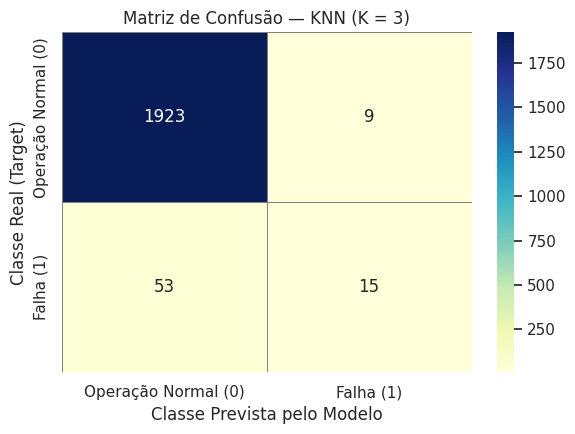

Acurácia Global no Teste: 0.9690


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# variáveis de sensores numéricos e as colunas de tipo geradas pelo get_dummies
base_features = [
    'Air temperature [K]', 'Process temperature [K]',
    'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]'
]

# percorre todo o df  buscando as colunas que comecam com Type_
type_cols = [col for col in df_model_knn.columns if col.startswith('Type_')]

# faz a união entre a base de features e da types convertida para binário
all_features = base_features + type_cols

X = df_model_knn[all_features]
y = df_model_knn['Target']  # 0 = Operação Normal, 1 = Falha

print(f"Features utilizadas no KNN: {all_features}")
print(f"Dimensões de X: {X.shape} | Dimensões de y: {y.shape}")

# (Treino e Teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# padronização da escala
scaler_knn = StandardScaler()
X_train_scaled = scaler_knn.fit_transform(X_train)
X_test_scaled = scaler_knn.transform(X_test)

# cria uma lista de k
k_values = range(1, 20, 2)
# cria uma lista de do score da validacao
cv_scores = []

# itera todos os k
for k in k_values:
    knn_cv = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_cv, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

# k mais performatico
optimal_k_knn = k_values[np.argmax(cv_scores)]

# treinamento do modelo
knn_model = KNeighborsClassifier(n_neighbors=optimal_k_knn)
knn_model.fit(X_train_scaled, y_train)

# avaliacao de desempenho nos testes
y_pred = knn_model.predict(X_test_scaled)

print("\n--- RELATÓRIO DE CLASSIFICAÇÃO (KNN) ---")
print(classification_report(y_test, y_pred, target_names=['Operação Normal', 'Falha']))

cm = confusion_matrix(y_test, y_pred)
labels = ['Operação Normal (0)', 'Falha (1)']

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    linewidths=0.5,
    linecolor='gray'
)
plt.title(f'Matriz de Confusão — KNN (K = {optimal_k_knn})')
plt.xlabel('Classe Prevista pelo Modelo')
plt.ylabel('Classe Real (Target)')
plt.tight_layout()
plt.show()
print(f"Acurácia Global no Teste: {accuracy_score(y_test, y_pred):.4f}")

# 4. Persistência e Simulação de Reutilização

- Inserção dos dados
- Salvar o modelo já treinado

#4.1 SERIALIZAÇÃO DOS ARTEFATOS DE MACHINE LEARNING

Nesta etapa, realizamos a serialização dos artefatos do pipeline preditivo em disco utilizando a biblioteca joblib, visando a operacionalização da solução em ambiente de produção:

modelo_knn_manutencao.joblib: Salva o algoritmo KNN calibrado, permitindo executar inferências imediatas sem a necessidade de re-treinar o modelo a cada requisição.

scaler_knn_manutencao.joblib: Preserva o objeto StandardScaler ajustado no treino, garantindo a padronização exata dos novos dados de entrada sem vazamento de dados (data leakage).

colunas_treino.joblib: Armazena a estrutura e a ordem oficial das colunas (all_features), prevenindo erros de formato e incompatibilidade de esquema no ambiente fabril.

In [ ]:
# Salvando os objetos gerados pelo seu colega (knn_model, scaler_knn, all_features)
joblib.dump(knn_model, 'modelo_knn_manutencao.joblib')
joblib.dump(scaler_knn, 'scaler_knn_manutencao.joblib')
joblib.dump(all_features, 'colunas_treino.joblib')

print(" Todos os artefatos da Squad foram persistidos com sucesso:")
print("   - modelo_kmeans_manutencao.joblib (Pipeline K-Means)")
print("   - modelo_knn_manutencao.joblib    (Modelo KNN treinado)")
print("   - scaler_knn_manutencao.joblib    (StandardScaler do KNN)")
print("   - colunas_treino.joblib           (Features oficiais: all_features)\n")

 Todos os artefatos da Squad foram persistidos com sucesso:
   - modelo_kmeans_manutencao.joblib (Pipeline K-Means)
   - modelo_knn_manutencao.joblib    (Modelo KNN treinado)
   - scaler_knn_manutencao.joblib    (StandardScaler do KNN)
   - colunas_treino.joblib           (Features oficiais: all_features)



#4.2 BLOCO DE SIMULAÇÃO DE PRODUÇÃO (SIMULAÇÃO DE ENDPOINT / REQUISIÇÃO API)

Nesta etapa, implementamos a função simular_telemetria_iot_api, que consolida os três pilares analíticos desenvolvidos pela squad em um fluxo simulado de produção via requisição API:

Carregamento de Artefatos: Restaura os arquivos serializados (.joblib) para garantir inferências instantâneas com padronização rigorosa dos dados.

Validação de Alertas (Apriori): Identifica se os sensores acionam gatilhos críticos operacionais (alta temperatura, torque ou rotação).

Segmentação de Desgaste (K-Means): Classifica a máquina em um perfil de comportamento (ex: Operação Nominal ou Estresse Mecânico).

Predição Preditiva e Tomada de Decisão (KNN): Calcula a probabilidade de falha iminente e emite o diagnóstico final, recomendando parada imediata para manutenção corretiva ou continuidade da operação nominal.

In [ ]:
def simular_telemetria_iot_api(payload_dict):
    """
    Simula o recebimento de telemetria IoT via API/Dashboard.
    Consome os gatilhos do Apriori, a clusterização do K-Means e a predição do KNN.
    """
    # 1. Carregamento dos artefatos serializados (.joblib)
    kmeans_pipeline = joblib.load('modelo_kmeans_manutencao.joblib')
    knn_modelo = joblib.load('modelo_knn_manutencao.joblib')
    knn_scaler = joblib.load('scaler_knn_manutencao.joblib')
    colunas_esperadas = joblib.load('colunas_treino.joblib')

    # 2. Apriori: Validação dos Gatilhos Críticos (Regras do Colega)
    temp_k = payload_dict.get('Air temperature [K]', 0)
    rotacao_rpm = payload_dict.get('Rotational speed [rpm]', 0)
    torque_nm = payload_dict.get('Torque [Nm]', 0)

    gatilhos_apriori = []
    if temp_k > 302:
        gatilhos_apriori.append("Temperatura_alta (> 302 K)")
    if rotacao_rpm > 1750:
        gatilhos_apriori.append("Alta_rotacao (> 1750 RPM)")
    if torque_nm > 50:
        gatilhos_apriori.append("Alto_Torque (> 50 Nm)")

    # 3. K-Means: Inferência de Perfil via Pipeline do Scikit-Learn
    features_sensores = [
        'Air temperature [K]',
        'Process temperature [K]',
        'Rotational speed [rpm]',
        'Torque [Nm]',
        'Tool wear [min]'
    ]
    df_sensor = pd.DataFrame([payload_dict])[features_sensores]
    cluster_predito = kmeans_pipeline.predict(df_sensor)[0]

    mapa_clusters = {
        0: "Operação Nominal / Estável",
        1: "Sobrecarga Térmica / Desgaste Moderado",
        2: "Estresse Mecânico Crítico / Alta Rotatividade"
    }
    perfil_nome = mapa_clusters.get(cluster_predito, f"Cluster {cluster_predito}")

    # 4. KNN: Classificação Supervisionada
    df_input = pd.DataFrame([payload_dict])
    df_encoded = pd.get_dummies(df_input)
    df_final_knn = df_encoded.reindex(columns=colunas_esperadas, fill_value=0)

    X_scaled_knn = knn_scaler.transform(df_final_knn)
    pred_knn = knn_modelo.predict(X_scaled_knn)[0]
    prob_falha = knn_modelo.predict_proba(X_scaled_knn)[0][1]

    # 5. Emissão da Resposta do Dashboard
    print("=" * 75)
    print(" REQUISIÇÃO RECEBIDA DE TELEMETRIA IOT")
    print("=" * 75)
    print(f"Payload de Entrada: {payload_dict}\n")
    print(f" [Apriori] Regras de Alerta Ativas:  {', '.join(gatilhos_apriori) if gatilhos_apriori else 'Nenhuma (Leitura Nominal)'}")
    print(f" [K-Means] Perfil de Desgaste:       Cluster {cluster_predito} ({perfil_nome})")
    print(f" [KNN] Probabilidade de Falha:       {prob_falha * 100:.2f}%")

    if pred_knn == 1 or prob_falha > 0.40:
        print("\n DIAGNÓSTICO FINAL: ALERTA CRÍTICO — FALHA IMINENTE DETECTADA")
        print(" AÇÃO RECOMENDADA: Paralisar equipamento e acionar Manutenção Corretiva.")
    else:
        print("\n DIAGNÓSTICO FINAL: OPERAÇÃO SAUDÁVEL DENTRO DOS PARÂMETROS")
        print(" AÇÃO RECOMENDADA: Manter plano habitual de monitoramento preditivo.")
    print("=" * 75 + "\n")

#4.3 SIMULAÇÃO DE CASOS DE TESTE EM PRODUÇÃO

Nesta etapa, realizamos a validação prática do pipeline integrado submetendo duas leituras de telemetria IoT simuladas que representam extremos operacionais da fábrica:

Cenário 1 — Operação Estável (leitura_estavel): Envia dados dentro dos limites nominais de temperatura, torque e desgaste da ferramenta. Valida se o sistema reconhece a normalidade sem disparar alertas falsos ou intervenções desnecessárias.

Cenário 2 — Operação Crítica (leitura_critica): Simula um equipamento sob severo estresse mecânico e térmico (temperatura elevada, alto torque e ferramentas desgastadas). Valida a capacidade do pipeline de ativar as regras do Apriori, classificar o cluster de estresse no K-Means e emitir o diagnóstico de Falha Iminente via KNN para recomendar a parada corretiva.

In [ ]:
leitura_estavel = {
    'Air temperature [K]': 298.1,
    'Process temperature [K]': 308.6,
    'Rotational speed [rpm]': 1500,
    'Torque [Nm]': 38.0,
    'Tool wear [min]': 10,
    'Type': 'M'
}

leitura_critica = {
    'Air temperature [K]': 304.5,
    'Process temperature [K]': 313.8,
    'Rotational speed [rpm]': 1320,
    'Torque [Nm]': 65.0,
    'Tool wear [min]': 210,
    'Type': 'L'
}

simular_telemetria_iot_api(leitura_estavel)
simular_telemetria_iot_api(leitura_critica)

 REQUISIÇÃO RECEBIDA DE TELEMETRIA IOT
Payload de Entrada: {'Air temperature [K]': 298.1, 'Process temperature [K]': 308.6, 'Rotational speed [rpm]': 1500, 'Torque [Nm]': 38.0, 'Tool wear [min]': 10, 'Type': 'M'}

 [Apriori] Regras de Alerta Ativas:  Nenhuma (Leitura Nominal)
 [K-Means] Perfil de Desgaste:       Cluster 1 (Sobrecarga Térmica / Desgaste Moderado)
 [KNN] Probabilidade de Falha:       0.00%

 DIAGNÓSTICO FINAL: OPERAÇÃO SAUDÁVEL DENTRO DOS PARÂMETROS
 AÇÃO RECOMENDADA: Manter plano habitual de monitoramento preditivo.

 REQUISIÇÃO RECEBIDA DE TELEMETRIA IOT
Payload de Entrada: {'Air temperature [K]': 304.5, 'Process temperature [K]': 313.8, 'Rotational speed [rpm]': 1320, 'Torque [Nm]': 65.0, 'Tool wear [min]': 210, 'Type': 'L'}

 [Apriori] Regras de Alerta Ativas:  Temperatura_alta (> 302 K), Alto_Torque (> 50 Nm)
 [K-Means] Perfil de Desgaste:       Cluster 0 (Operação Nominal / Estável)
 [KNN] Probabilidade de Falha:       66.67%

 DIAGNÓSTICO FINAL: ALERTA CRÍTICO — F

### Limitações da Solução, Prevenção de Leakage e Próximos Passos

#### 1. Prevenção de Data Leakage

O arquivo `scaler_knn_manutencao.joblib`, salvo durante o treinamento, será reutilizado para padronizar os novos dados recebidos pela API. Dessa forma, os dados passam pelo mesmo processo utilizado no treinamento, mantendo a consistência das previsões e evitando o Data Leakage.

#### 2. Limitações em Produção

- **Desempenho do KNN:** O KNN precisa comparar cada novo dado com os registros utilizados no treinamento para encontrar os mais próximos. Em uma fábrica com muitos sensores enviando informações em tempo real, esse processo pode ficar mais lento e afetar o tempo de resposta.
- **Mudanças nos dados (*Concept Drift*):** Com o tempo, os sensores podem apresentar novos padrões de funcionamento, principalmente após a troca de peças ou mudanças na operação das máquinas. Por isso, pode ser necessário atualizar os modelos e realizar novos treinamentos para manter a qualidade das previsões.

#### 3. Próximos Passos

1. **Testar outros modelos:** Avaliar algoritmos como Random Forest e XGBoost, que podem apresentar melhor desempenho e velocidade de resposta em cenários com muitos dados.
2. **Criar uma API com FastAPI:** Disponibilizar o modelo por meio de uma API, criando uma rota `POST /predict` para receber os dados e retornar as previsões. Também será utilizada a biblioteca `Pydantic` para validar as informações recebidas.
3. **Utilizar Docker:** Criar um container com a aplicação e os arquivos dos modelos, facilitando sua execução e implantação em serviços na nuvem, como Google Cloud Run e AWS Lambda, permitindo a integração com o Dashboard da fábrica.